# Análise experimental dos detectores

Este notebook lê os resultados do experimento, cria tabelas e exporta figuras para `results/figures/`. As análises usam o CSV de métricas por resolução e os scores brutos por imagem.

A imagem isolada da fonte RAISE é removida, pois não representa adequadamente essa fonte real.

In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style='whitegrid', context='notebook')

ROOT = Path.cwd()
if not (ROOT / 'results').is_dir():
    ROOT = ROOT.parent

RESULTS_DIR = ROOT / 'results'
FIGURES_DIR = RESULTS_DIR / 'figures'
FIGURES_DIR.mkdir(exist_ok=True)

METRICS_PATH = RESULTS_DIR / 'metrics_by_resolution.csv'
RAW_PATH = RESULTS_DIR / 'experiment_resolution.csv'

metrics = pd.read_csv(METRICS_PATH)
raw = pd.read_csv(RAW_PATH)
raw = raw[~((raw['Tipo_Label'] == 'Real') & (raw['Fonte_Real'].str.lower() == 'raise'))].copy()

RESOLUTION_ORDER = ['original', '256x256', '512x512', '1024x1024']
metrics['Resolução'] = pd.Categorical(metrics['Resolução'], RESOLUTION_ORDER, ordered=True)
raw['Resolução'] = pd.Categorical(raw['Resolução'], RESOLUTION_ORDER, ordered=True)

SHORT_NAMES = {
    'UnivFD (CLIP ViT-L/14)': 'UnivFD',
    'CNNDetection (Blur+JPEG 0.5)': 'CNNDetection',
    'NPR (ResNet50)': 'NPR',
    'B-Free (DINOv2)': 'B-Free',
    'SPAI (Spectral AI-Generated Image Detector)': 'SPAI',
    'Ensemble (média)': 'Ensemble média',
    'Ensemble (mediana)': 'Ensemble mediana',
    'Ensemble (percentil 75)': 'Ensemble P75',
    'Ensemble (percentil 90)': 'Ensemble P90',
    'Ensemble (máximo)': 'Ensemble máximo',
    'Ensemble (mínimo)': 'Ensemble mínimo',
    'Ensemble (votação majoritária)': 'Ensemble votação',
}
metrics['Nome curto'] = metrics['Modelo'].replace(SHORT_NAMES)

print(f'Imagens por resolução: {raw["Indice_Dataset"].nunique()}')
print(f'Figuras serão salvas em: {FIGURES_DIR}')

Imagens por resolução: 1650
Figuras serão salvas em: c:\Users\Administrador\Documents\Projetos\tcc_repository\results\figures


## Verificação da amostra

Antes de interpretar métricas, confirme a composição real/fake e a presença das quatro condições de resolução.

In [11]:
sample_summary = (raw.groupby(['Resolução', 'Tipo_Label'], observed=True)['Indice_Dataset']
                 .nunique().unstack(fill_value=0))
sample_summary['Total'] = sample_summary.sum(axis=1)
display(sample_summary)

assert raw.groupby('Indice_Dataset', observed=True)['Resolução'].nunique().eq(4).all(), 'Há imagens sem todas as resoluções.'

Tipo_Label,Fake,Real,Total
Resolução,,,
original,900,750,1650
256x256,900,750,1650
512x512,900,750,1650
1024x1024,900,750,1650


## F1-score por detector e resolução

O F1-score combina precisão e recall.

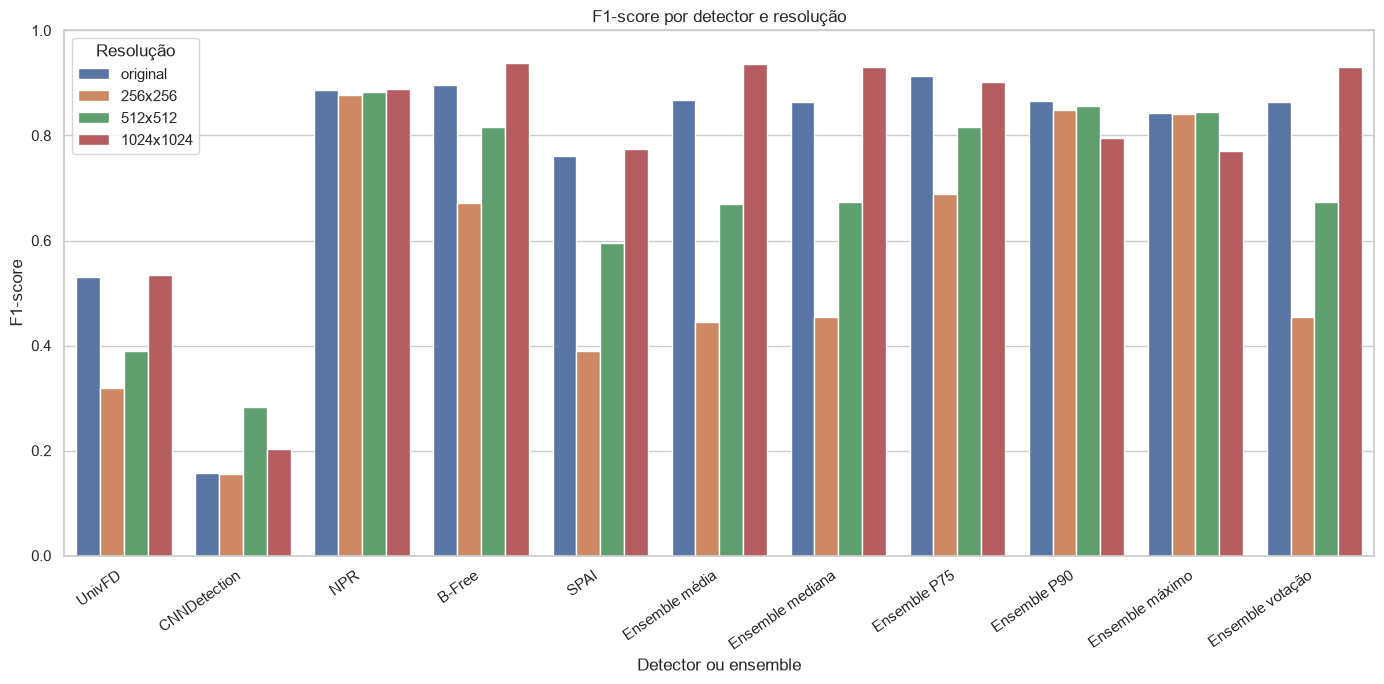

In [12]:
plot_data = metrics[metrics['Modelo'] != 'Ensemble (mínimo)'].copy()
plt.figure(figsize=(14, 7))
sns.barplot(data=plot_data, x='Nome curto', y='F1-score', hue='Resolução')
plt.ylim(0, 1)
plt.xlabel('Detector ou ensemble')
plt.ylabel('F1-score')
plt.title('F1-score por detector e resolução')
plt.xticks(rotation=35, ha='right')
plt.legend(title='Resolução')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'f1_por_modelo_e_resolucao.png', dpi=300, bbox_inches='tight')
plt.show()

## Recall e especificidade

O canto superior direito é desejável: alto recall detecta mais imagens fake e alta especificidade reduz falsos positivos em imagens reais.

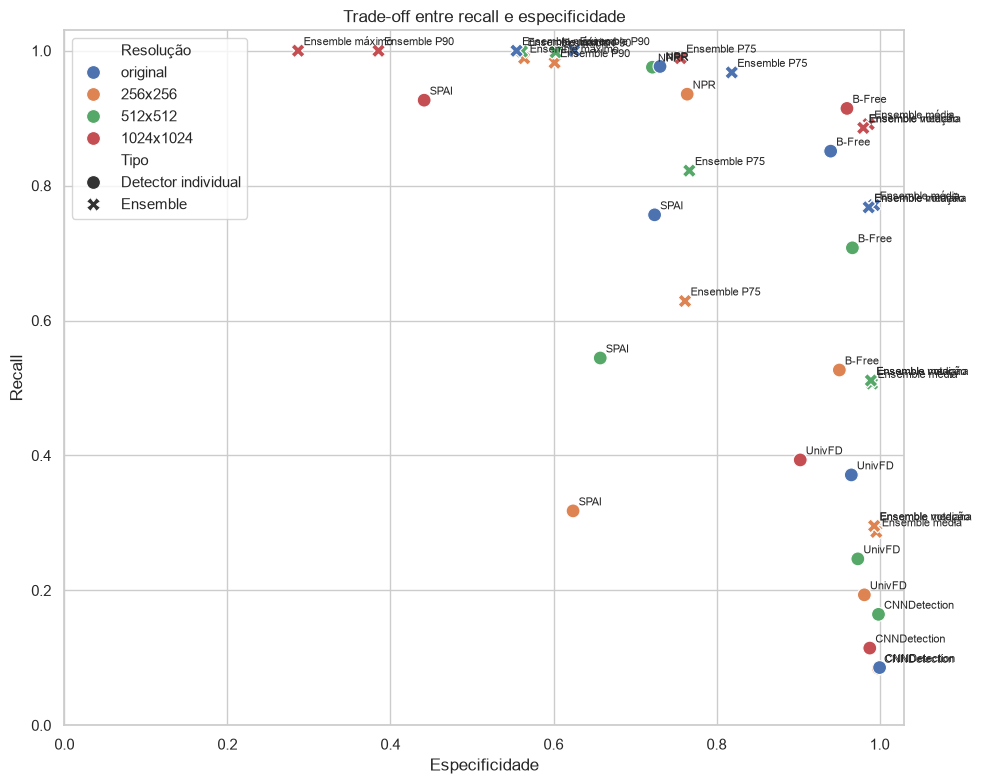

In [13]:
plot_data = metrics[metrics['Modelo'] != 'Ensemble (mínimo)'].copy()
plt.figure(figsize=(10, 8))
sns.scatterplot(data=plot_data, x='Especificidade', y='Recall', hue='Resolução', style='Tipo', s=100)
for _, row in plot_data.iterrows():
    plt.annotate(row['Nome curto'], (row['Especificidade'], row['Recall']), xytext=(4, 4), textcoords='offset points', fontsize=8)
plt.xlim(0, 1.03)
plt.ylim(0, 1.03)
plt.xlabel('Especificidade')
plt.ylabel('Recall')
plt.title('Trade-off entre recall e especificidade')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'recall_vs_especificidade.png', dpi=300, bbox_inches='tight')
plt.show()

## AUC-ROC por método

A AUC-ROC avalia a separação entre reais e fakes usando a distribuição completa dos scores, sem depender somente do threshold 0,5.

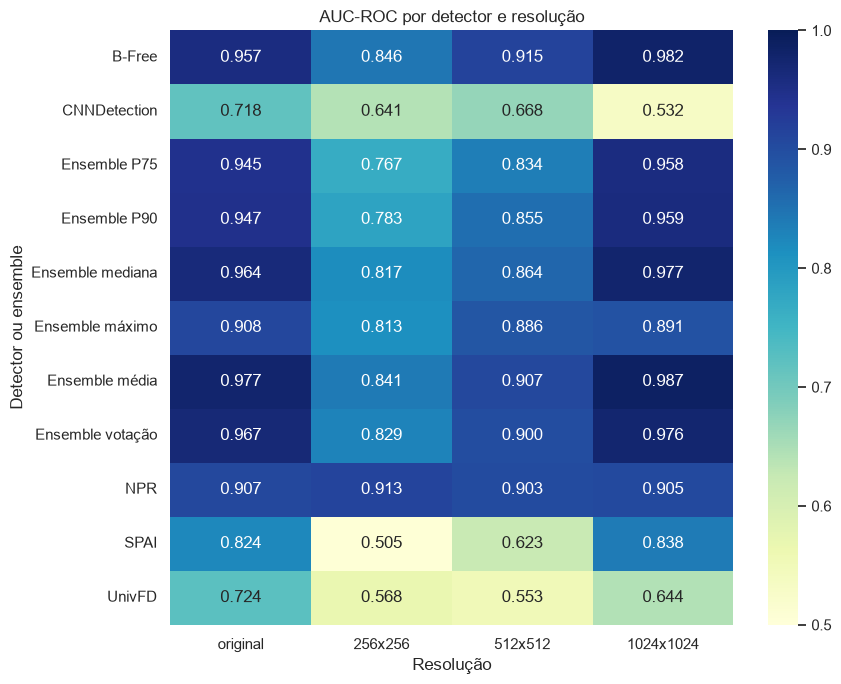

In [14]:
auc_table = (metrics[metrics['Modelo'] != 'Ensemble (mínimo)']
             .pivot(index='Nome curto', columns='Resolução', values='AUC-ROC')
             .reindex(columns=RESOLUTION_ORDER))
plt.figure(figsize=(9, 7))
sns.heatmap(auc_table, annot=True, fmt='.3f', cmap='YlGnBu', vmin=0.5, vmax=1)
plt.xlabel('Resolução')
plt.ylabel('Detector ou ensemble')
plt.title('AUC-ROC por detector e resolução')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'auc_roc_por_modelo_e_resolucao.png', dpi=300, bbox_inches='tight')
plt.show()

## Comparação das estratégias de ensemble

Esta figura indica se combinar os detectores supera os modelos individuais e qual agregação mantém melhor desempenho entre resoluções.

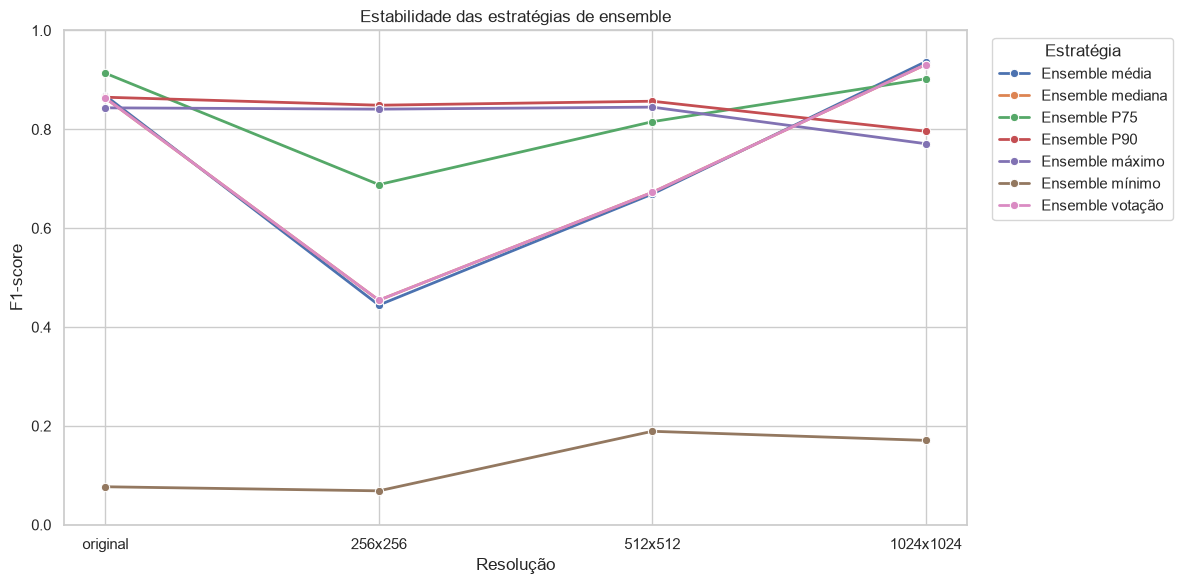

In [15]:
ensemble_data = metrics[metrics['Tipo'] == 'Ensemble'].copy()
plt.figure(figsize=(12, 6))
sns.lineplot(data=ensemble_data, x='Resolução', y='F1-score', hue='Nome curto', marker='o', linewidth=2)
plt.ylim(0, 1)
plt.xlabel('Resolução')
plt.ylabel('F1-score')
plt.title('Estabilidade das estratégias de ensemble')
plt.legend(title='Estratégia', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'ensembles_por_resolucao.png', dpi=300, bbox_inches='tight')
plt.show()

## Generalização por gerador

O recall abaixo mostra, para 512×512, quais geradores sintéticos são mais difíceis de detectar. Cada painel representa um detector.

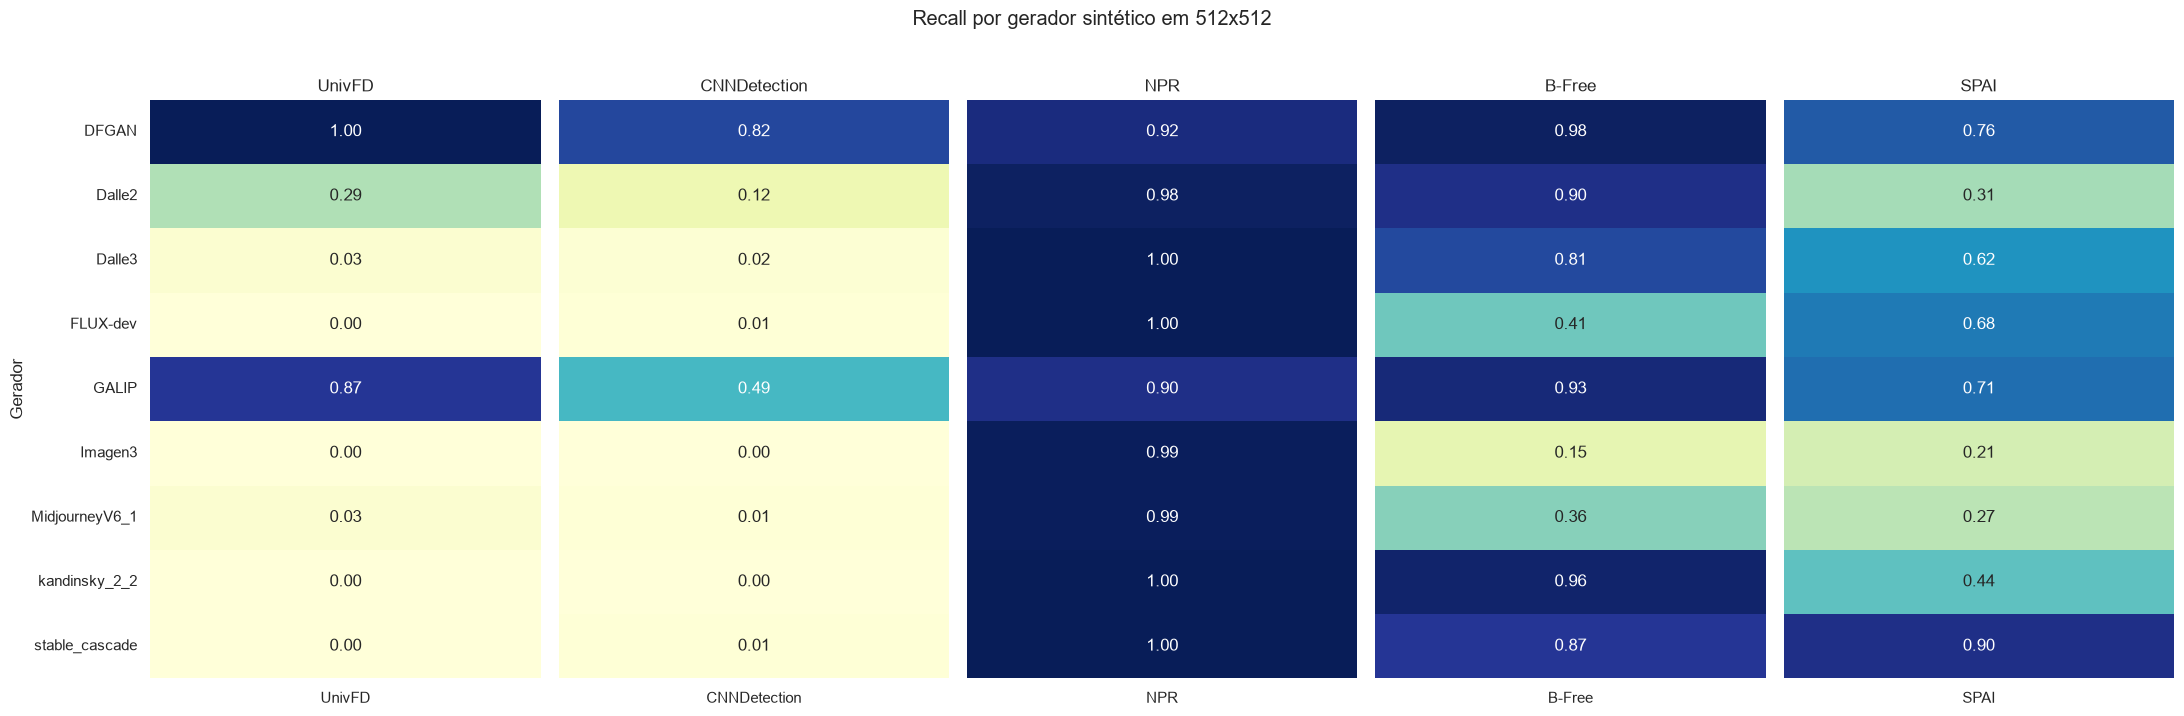

In [16]:
DETECTOR_COLUMNS = [
    'UnivFD (CLIP ViT-L/14)',
    'CNNDetection (Blur+JPEG 0.5)',
    'NPR (ResNet50)',
    'B-Free (DINOv2)',
    'SPAI (Spectral AI-Generated Image Detector)',
]

fake_512 = raw[(raw['Tipo_Label'] == 'Fake') & (raw['Resolução'] == '512x512')]
long_fake = fake_512.melt(id_vars='Modelo_Gerador', value_vars=DETECTOR_COLUMNS, var_name='Detector', value_name='Score')
long_fake['Detector'] = long_fake['Detector'].replace(SHORT_NAMES)
recall_generator = long_fake.assign(Detectado=lambda data: data['Score'] >= 0.5).groupby(['Detector', 'Modelo_Gerador'])['Detectado'].mean().reset_index()

fig, axes = plt.subplots(1, 5, figsize=(22, 7), sharey=True)
for ax, detector in zip(axes, ['UnivFD', 'CNNDetection', 'NPR', 'B-Free', 'SPAI']):
    table = recall_generator[recall_generator['Detector'] == detector].pivot(index='Modelo_Gerador', columns='Detector', values='Detectado')
    sns.heatmap(table, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, cbar=False, ax=ax)
    ax.set_title(detector)
    ax.set_xlabel('')
    ax.set_ylabel('Gerador' if detector == 'UnivFD' else '')
fig.suptitle('Recall por gerador sintético em 512x512', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'recall_por_gerador_512.png', dpi=300, bbox_inches='tight')
plt.show()

## Falsos positivos por fonte real

A taxa apresentada é a proporção de imagens reais classificadas como fake. Valores altos revelam dificuldade de generalização para aquela fonte de imagens reais.

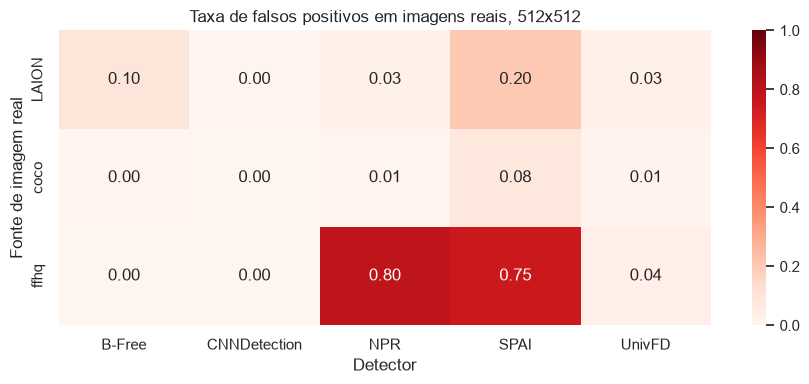

In [17]:
real_512 = raw[(raw['Tipo_Label'] == 'Real') & (raw['Resolução'] == '512x512')]
long_real = real_512.melt(id_vars='Fonte_Real', value_vars=DETECTOR_COLUMNS, var_name='Detector', value_name='Score')
long_real['Detector'] = long_real['Detector'].replace(SHORT_NAMES)
false_positive_rate = long_real.assign(Falso_positivo=lambda data: data['Score'] >= 0.5).groupby(['Fonte_Real', 'Detector'])['Falso_positivo'].mean().reset_index()

fpr_table = false_positive_rate.pivot(index='Fonte_Real', columns='Detector', values='Falso_positivo')
plt.figure(figsize=(9, 4))
sns.heatmap(fpr_table, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1)
plt.xlabel('Detector')
plt.ylabel('Fonte de imagem real')
plt.title('Taxa de falsos positivos em imagens reais, 512x512')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'falsos_positivos_por_fonte_512.png', dpi=300, bbox_inches='tight')
plt.show()

## Efeito do redimensionamento no score médio do ensemble

Cada ponto representa a mesma imagem em condições diferentes. A leitura deve ser combinada com F1, recall e especificidade; variação de score sozinha não prova melhora ou piora do detector.

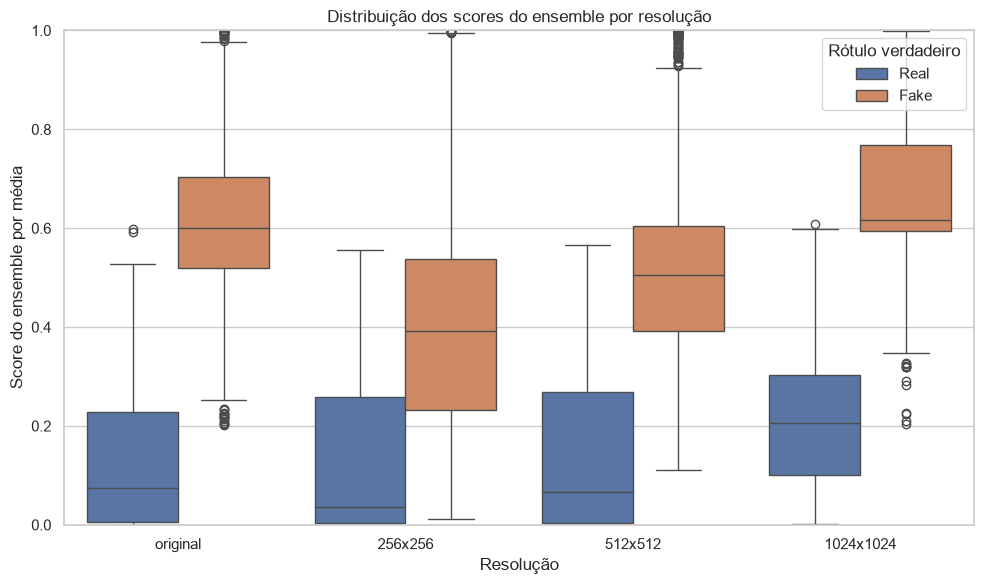

In [18]:
score_shift = raw[['Indice_Dataset', 'Tipo_Label', 'Resolução', 'Média']].copy()
plt.figure(figsize=(10, 6))
sns.boxplot(data=score_shift, x='Resolução', y='Média', hue='Tipo_Label', order=RESOLUTION_ORDER)
plt.ylim(0, 1)
plt.xlabel('Resolução')
plt.ylabel('Score do ensemble por média')
plt.title('Distribuição dos scores do ensemble por resolução')
plt.legend(title='Rótulo verdadeiro')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'distribuicao_score_ensemble.png', dpi=300, bbox_inches='tight')
plt.show()